In [ ]:
import sys 
sys.path.append('../src')

from data_processing.load import load_and_preprocess_data

from data_processing.utils import load_checkpoint, save_checkpoint, run_inference_bnn, run_svi
from models.model import model

import jax
import jax.numpy as jnp
import numpy as np
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt
from jax import random
import time
from numpyro.infer import MCMC, NUTS, Predictive, SVI, Trace_ELBO
import arviz as az
import scipy
from scipy.stats import percentileofscore
from numpyro.infer.autoguide import AutoNormal
from numpyro.optim import Adam



In [2]:
jax.config.update('jax_num_cpu_devices', 6) # I have 8 physical cores

### Load data and preprocess
- wind direction transformed from degree using sin and cos
- select one bid zone
- include UMM downtime data
- calculate capacity factor
- scale input features and meta data

Shapes:
- X: (timestamps, wind parks, features)
- Y: (timestamps)
- sites_meta: (wind parks, 1)

In [3]:
from operator import itemgetter
data = load_and_preprocess_data()
(X_train, X_test, Y_train_gen, Y_test_gen,
 Y_train_cf, Y_test_cf, Y_train_aval, Y_test_aval,
 sites_meta, feature_cols) = itemgetter(
    "X_train","X_test","Y_train_gen","Y_test_gen",
    "Y_train_cf","Y_test_cf","Y_train_aval","Y_test_aval",
    "sites_meta","feature_cols"
)(data)


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:59: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


QUEUEING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?it…

PROCESSING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?…

COLLECTING RESULTS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?,…

Preprocessing done. X_train shape: (19130, 6, 6)
Preprocessing done. X_test shape: (2161, 6, 6)


### Simple BNN
input: (timestamps, wind parks, features)
output: (timestamps)


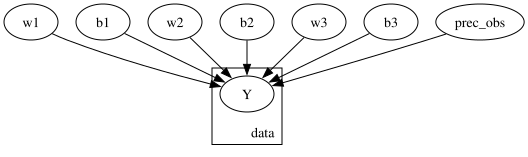

In [4]:
import numpyro
numpyro.render_model(
    model,
    model_args=(X_test,),
)

In [5]:
D_H = 32
args = {
    'num_warmup': 10,
    'num_samples': 30,
    'num_chains': 2,
}

rng_key, rng_key_predict = random.split(random.PRNGKey(0))

Run MCMC

In [13]:
samples = run_inference_bnn(model, args, rng_key, X_train, Y_train_gen, D_H)

  0%|          | 0/40 [00:00<?, ?it/s]

  0%|          | 0/40 [00:00<?, ?it/s]


                mean       std    median      5.0%     95.0%     n_eff     r_hat
     b1[0]      0.63      0.48      0.55      0.00      1.68      6.02      2.21
     b1[1]      1.01      0.70      1.34      0.15      1.69      1.05      5.04
     b1[2]     -0.22      2.03      0.21     -2.57      1.78      1.03     10.53
     b1[3]     -1.52      0.42     -1.71     -1.95     -0.78      3.57      3.58
     b1[4]     -1.04      0.68     -1.49     -1.58      0.46      1.51      2.16
     b1[5]      0.90      1.17      1.37     -0.72      1.99      1.11      3.28
     b1[6]      0.40      1.00      0.15     -0.62      1.79      1.07      5.31
     b1[7]      1.61      0.38      1.73      1.02      2.19      5.49      1.90
     b1[8]      1.64      0.84      1.32      0.84      2.83      1.12      3.78
     b1[9]      0.34      1.74      0.94     -2.26      1.97      1.11      7.03
    b1[10]     -0.28      0.23     -0.32     -0.47      0.20      8.88      1.51
    b1[11]     -0.28      1

In [14]:
save_checkpoint(samples, "model", args, rng_key)

Saved checkpoint for model 'model': ../../checkpoints/model_2025-10-23_13-34-44_gen.pkl


'../../checkpoints/model_2025-10-23_13-34-44_gen.pkl'

Load checkpoint (MCMC)

In [ ]:
state_ckp = load_checkpoint(file_name='model_2025-10-23_09-03-57_gen') # model_2025-10-21_14-28-15_gen, model_2025-10-23_09-03-57_gen
samples_ckp = state_ckp['samples']
args_ckp = state_ckp['args']
rng_key_ckp = state_ckp['rng_key']
rng_key_ckp, rng_key_predict_ckp = random.split(rng_key_ckp)

In [79]:
state_ckp

{'model_name': 'model',
 'timestamp': '2025-10-23_09-03-57',
 'samples': {'b1': Array([[ 0.57222325,  1.6820582 ,  1.7821139 , ...,  1.7816602 ,
          -0.21941595, -0.0751695 ],
         [ 0.5705593 ,  1.6822757 ,  1.7809721 , ...,  1.7815166 ,
          -0.21659446, -0.07514431],
         [ 0.5693121 ,  1.6824492 ,  1.7801178 , ...,  1.7813473 ,
          -0.21437477, -0.07515094],
         ...,
         [ 3.0865943 , -0.05618512, -2.167161  , ..., -0.03365121,
           0.22921066, -0.27022687],
         [ 2.4290605 , -0.0123035 , -2.2818758 , ...,  0.31276423,
           0.25807035,  0.01354679],
         [ 2.3933284 ,  0.03974137, -2.211987  , ...,  0.35178652,
           0.18646516, -0.23827958]], dtype=float32),
  'b2': Array([[ 0.3606623 ,  0.04003087,  1.7821027 , ...,  1.9233145 ,
           1.3937806 , -1.4203765 ],
         [ 0.36688098,  0.03798133,  1.7897596 , ...,  1.9224693 ,
           1.4033011 , -1.4233723 ],
         [ 0.37126198,  0.03656369,  1.7952714 , ...,

In [68]:
preds_MCMC = Predictive(model, samples_ckp)(rng_key_predict_ckp, X_test)['Y']

Run VI

In [23]:
guide = AutoNormal(model)
svi_result = run_svi(model, guide, rng_key, X_train, Y_train_gen)
params = svi_result.params
preds_VI = Predictive(model, guide=guide, params=params, num_samples=500)(rng_key_predict, X_test)['Y']


Final ELBO loss: 2241990.250


### Evaluation

In [69]:
preds = preds_MCMC # or preds_MCMC


In [70]:
preds_mean = preds.mean(axis=0)

# Percentiles, no assumption about shape of distribution, central 95% interval
# 95% of samples fall here
percentiles = np.percentile(preds, [2.5, 97.5], axis=0)
median = np.percentile(preds, 50, axis=0)

# Assumes posterior is Normal, symmetric around mean,
# If it's normal, 95% if samples fall here
preds_std = preds.std(axis=0)
normal_lower = preds_mean - 1.96 * preds_std
normal_upper = preds_mean + 1.96 * preds_std

# HDI (high densitiy interval), narrowest possible interval 
# Most probable 95% region
hdi = az.hdi(np.expand_dims(preds, axis=0), hdi_prob=0.95)

# Widths of different intervals (90% CI)
hdi_avg_width = (hdi[:,1]-hdi[:,0]).mean()
percentile_avg_width = (percentiles[1]-percentiles[0]).mean()
normal_ci_avg_width = (normal_upper - normal_lower).mean()

print(f"Percentile width: {percentile_avg_width}")
print(f"HDI width: {hdi_avg_width}")
print(f"Normal width: {normal_ci_avg_width}")

Percentile width: 261.5731174858165
HDI width: 258.6718231164805
Normal width: 317.32513427734375


In [71]:
rmse = jnp.sqrt(jnp.mean((preds_mean - Y_test_gen) ** 2))
print("Test RMSE:", rmse)

Test RMSE: 92.73922


Empirical coverage of percentiles

In [72]:

inside = (Y_test_gen >= percentiles[0]) & (Y_test_gen <= percentiles[1])
coverage_90 = inside.mean()
print(f"Empirical coverage (0.05–0.95): {coverage_90:.3f}")

below_median = (Y_test_gen <= median).mean()
print(f"Below median (should be ~0.5): {below_median:.3f}")


Empirical coverage (0.05–0.95): 0.886
Below median (should be ~0.5): 0.377


### Plots

Variational Inference loss

Final ELBO loss: 2241990.250


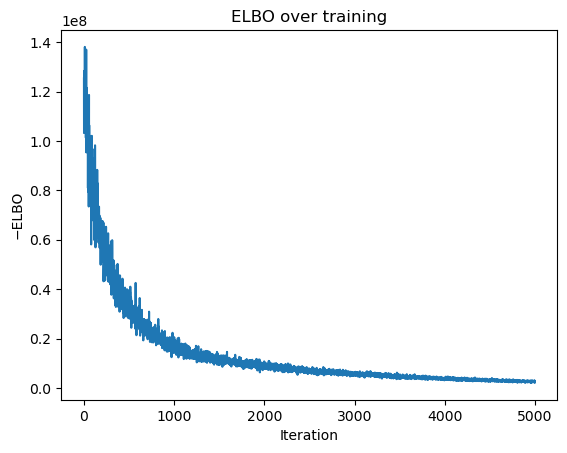

In [55]:
losses = svi_result.losses
print(f"Final ELBO loss: {losses[-1]:.3f}")
plt.plot(losses)
plt.title("ELBO over training")
plt.xlabel("Iteration")
plt.ylabel("−ELBO")
plt.show()


Residuals on training dataset

In [56]:
# positive residuals correspond to missed peaks
# positive tail: in general more underpredictions (train data)
pred_train_mcmc = Predictive(model, samples)(rng_key_predict, X_train)['Y']
pred_train_vi = Predictive(model, guide=guide, params=params, num_samples=500)(rng_key_predict, X_train)['Y']


In [57]:

pred_train = pred_train_vi # or pred_train_mcmc


skew: 0.30540776


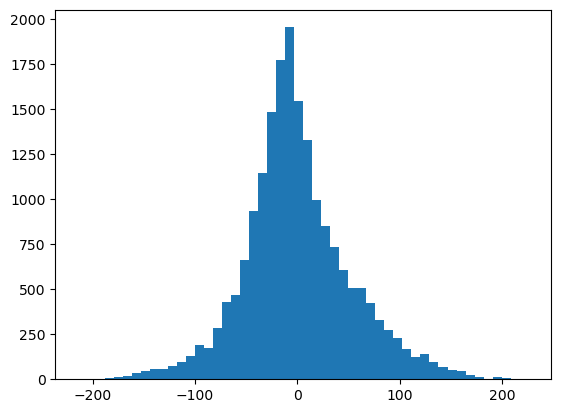

In [58]:
yhat = jnp.mean(pred_train, axis=0)
resid = Y_train_gen - yhat
print("skew:", scipy.stats.skew(np.array(resid)))
plt.hist(np.array(resid), bins=50); plt.show()



Different intervals (percentile vs. hdi vs. normal)

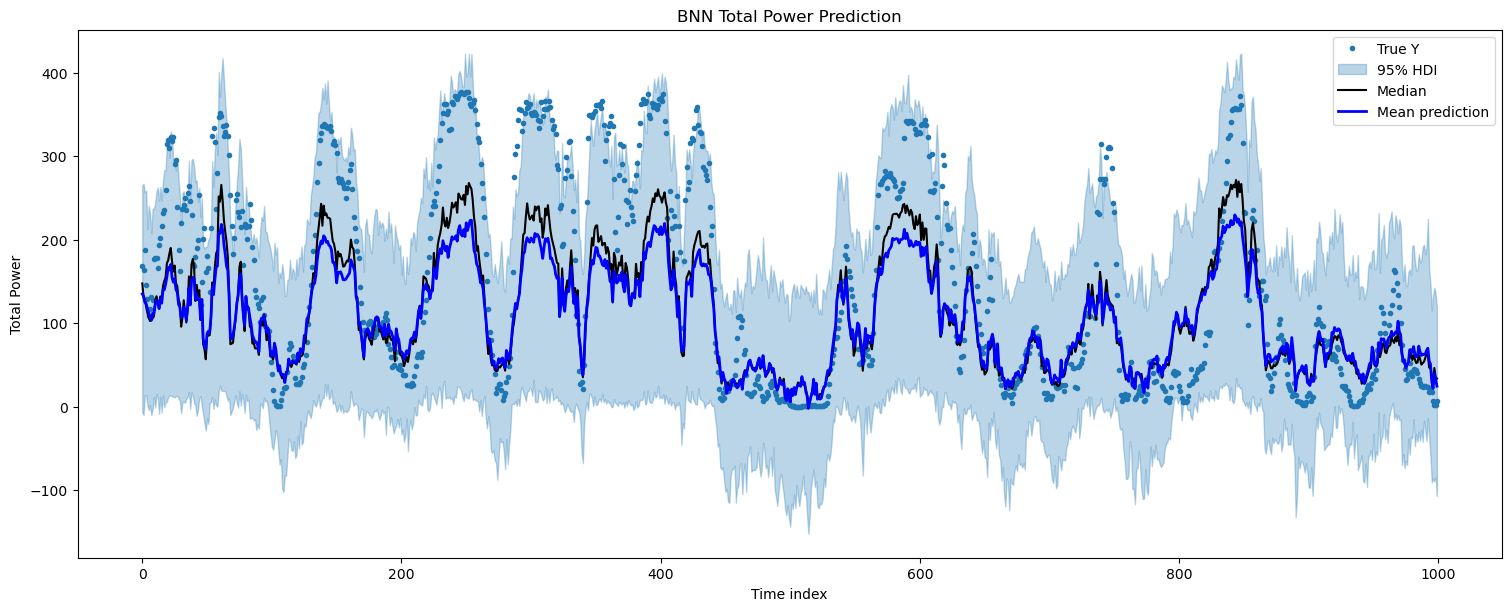

In [73]:
# Plot 90% CI
n_plot = 1000
fig, ax = plt.subplots(figsize=(15, 6), constrained_layout=True)
ax.plot(Y_test_gen[:n_plot], ".", label="True Y")
#ax.fill_between(np.arange(n_plot), normal_lower[:n_plot], normal_upper[:n_plot], label='Normal 95% CI', color="green", alpha=0.5)
ax.fill_between(np.arange(n_plot), hdi[:n_plot, 0], hdi[:n_plot, 1], color="C0", label="95% HDI", alpha=.3)
#ax.fill_between(np.arange(n_plot), percentiles[0, :n_plot], percentiles[1, :n_plot], label="Percentile 95% CI", color="lightblue", alpha=0.7)
ax.plot(median[:n_plot], label="Median", color="black")
ax.plot(preds_mean[:n_plot], "b", lw=2, label="Mean prediction")
ax.set(xlabel="Time index", ylabel="Total Power", title="BNN Total Power Prediction")
ax.legend()
plt.show()


Stacked HDI

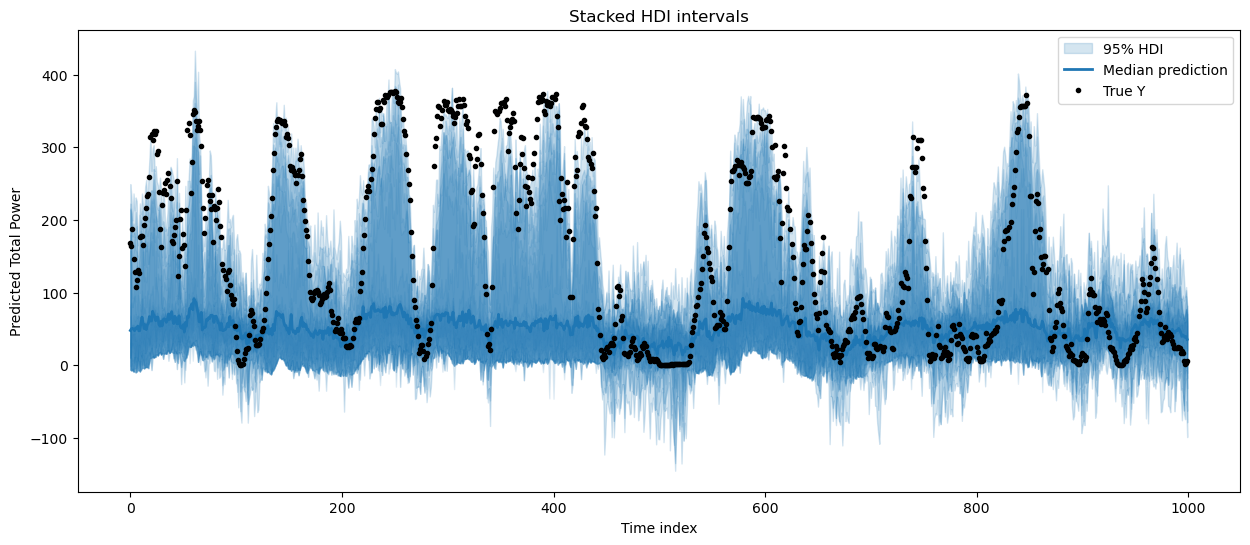

In [60]:
# Only plot first n_plot timesteps
n_plot = 1000

# Compute multiple HDI levels
hdi_probs = np.arange(0.05, 1.0, 0.05)
preds_hdi = np.expand_dims(preds, axis=0)
hdis = {float(p): az.hdi(preds_hdi, hdi_prob=float(p)) for p in hdi_probs}

X_new = np.arange(n_plot)
median = np.percentile(preds, 50, axis=0)

plt.figure(figsize=(15, 6))
max_p = max(hdis.keys())
for p in hdi_probs:
    hdi = hdis[p][:n_plot]
    alpha = 0.2 * float(p)
    label = f'{int(p*100)}% HDI' if p == max_p else None
    plt.fill_between(X_new, hdi[:, 0], hdi[:, 1], color='C0', alpha=alpha, label=label)

plt.plot(X_new, median[:n_plot], color='C0', lw=2, label='Median prediction')
plt.plot(Y_test_gen[:n_plot], ".", color="black", label="True Y")
plt.title("Stacked HDI intervals")
plt.xlabel("Time index")
plt.ylabel("Predicted Total Power")
plt.legend()
plt.show()


Std noise of model samples

<Axes: title={'center': 'std noise'}>

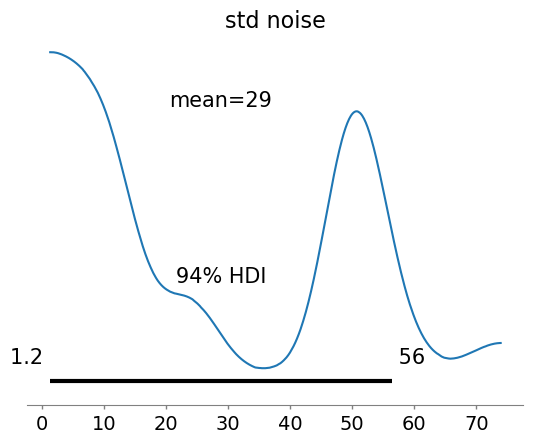

In [65]:
# Plot std noise
az.plot_posterior({'std noise': 1.0 / jnp.sqrt(samples['prec_obs'])})

PIT (Probability Integral Transform)
- Checks calibration of probabilistic forecasts
- Model well-calibrated -> values uniformly distributed
- For each observation $y_i$:
    - Take all model’s predictive samples for that data point
    - Compute how many of those samples are less than or equal to the actual observed value
    - PIT value $u_i = P_{\hat{Y_i}}​​(Y\leq y)$
    - with MCMC: $u_i \approx \frac{1}{S} \sum_{s=1}^S 1[y_i^{(s)}\leq y_i]$

PIT mean: 0.7161846367422491 (should be uniform if calibrated)


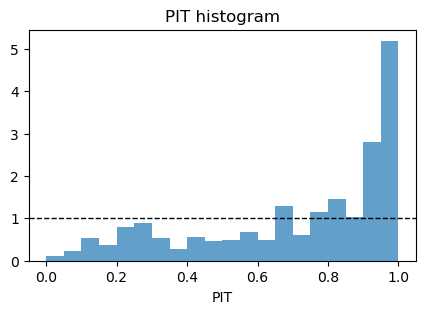

In [66]:
pits = np.array([percentileofscore(preds[:, t], Y_test_gen[t], kind='mean') / 100.0 for t in range(preds.shape[1])])
pits_mean = pits.mean()
print(f"PIT mean: {pits_mean} (should be uniform if calibrated)")

plt.figure(figsize=(5,3))
plt.hist(pits, bins=20, range=(0,1), density=True, alpha=0.7)
plt.axhline(1.0, color='k', ls='--', lw=1)  # reference
plt.xlabel("PIT")
plt.title("PIT histogram")
plt.show()